# 01 - 固定相机深度噪声与稳定性

        固定相机并观察静止表面，比较单像素与局部 patch median 的随机噪声。

        **需要手动确认**：相机固定、目标静止、`patch_size` 为奇数、测试点位于平坦区域。


> **运行方式**：从上到下逐个运行。深度数据内部统一使用米（m），统计结果同时显示毫米（mm）。
> 带有 `TODO` 的变量需要按实际实验配置修改。实时采集 cell 需要连接 RealSense D435/D435i。
> 建议使用 `opencv-contrib-python`（包含 `cv2.aruco`）、`pyrealsense2`、`numpy`、`pandas` 和 `matplotlib`。


## Block 1：导入库和参数设置

**输入**：采集参数。**输出**：输出目录和通用辅助函数。


In [12]:
import os
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd

# VS Code/Jupyter often starts with the non-interactive inline backend.
# Activate ipympl before importing pyplot so Block 4 can receive mouse clicks.
try:
    get_ipython().run_line_magic("matplotlib", "widget")
except Exception as exc:
    print("无法启用 Matplotlib widget，将在 Block 4 使用手动坐标:", exc)

import matplotlib.pyplot as plt

try:
    import pyrealsense2 as rs
except ImportError as exc:
    raise ImportError("缺少 pyrealsense2，请在连接 RealSense 的环境中安装它。") from exc

def find_project_root() -> Path:
    current = Path.cwd().resolve()
    for candidate in (current, *current.parents):
        if (candidate / "cam_calibration").is_dir():
            return candidate
    raise RuntimeError("无法定位项目根目录；请从 Xinyu 项目内启动 Jupyter。")

PROJECT_ROOT = find_project_root()
CALIBRATION_ROOT = PROJECT_ROOT / "cam_calibration"
INPUT_DIR = CALIBRATION_ROOT / "inputs"
OUTPUT_ROOT = CALIBRATION_ROOT / "outputs"
SHARED_DIR = OUTPUT_ROOT / "shared"
CONFIG_DIR = CALIBRATION_ROOT / "config"
for directory in (INPUT_DIR, OUTPUT_ROOT, SHARED_DIR, CONFIG_DIR):
    directory.mkdir(parents=True, exist_ok=True)

width, height, fps = 640, 480, 30
num_frames = 100
patch_size = 7
warmup_frames = 30
output_dir = OUTPUT_ROOT / "01_depth_noise"
output_dir.mkdir(parents=True, exist_ok=True)

if patch_size < 1 or patch_size % 2 == 0:
    raise ValueError("patch_size 必须是正奇数。")

def valid_values(values):
    values = np.asarray(values, dtype=float)
    return values[np.isfinite(values) & (values > 0)]

def depth_stats(values):
    values = np.asarray(values, dtype=float)
    valid = valid_values(values)
    if valid.size == 0:
        return dict(mean=np.nan, std=np.nan, min=np.nan, max=np.nan,
                    peak_to_peak=np.nan, valid_frame_ratio=0.0)
    return dict(mean=float(valid.mean()), std=float(valid.std(ddof=0)),
                min=float(valid.min()), max=float(valid.max()),
                peak_to_peak=float(np.ptp(valid)),
                valid_frame_ratio=float(valid.size / values.size))

print("输出目录:", output_dir.resolve())


输出目录: /home/masais/Xinyu/cam_calibration/outputs/01_depth_noise


## Block 2：启动 RealSense pipeline

**输出**：对齐器、深度比例和 color 内参。运行结束后由最后一个清理 cell 停止 pipeline。


In [13]:
pipeline = rs.pipeline()
config = rs.config()
config.enable_stream(rs.stream.color, width, height, rs.format.bgr8, fps)
config.enable_stream(rs.stream.depth, width, height, rs.format.z16, fps)

try:
    profile = pipeline.start(config)
    align = rs.align(rs.stream.color)
    depth_sensor = profile.get_device().first_depth_sensor()
    depth_scale = float(depth_sensor.get_depth_scale())
    color_profile = profile.get_stream(rs.stream.color).as_video_stream_profile()
    intr = color_profile.get_intrinsics()
    intrinsics = {"width": intr.width, "height": intr.height, "fx": intr.fx,
                  "fy": intr.fy, "cx": intr.ppx, "cy": intr.ppy,
                  "model": str(intr.model), "coeffs": list(intr.coeffs)}
    print("depth_scale:", depth_scale, "m/unit")
    print("fx={fx:.3f}, fy={fy:.3f}, cx={cx:.3f}, cy={cy:.3f}".format(**intrinsics))
    for _ in range(warmup_frames):
        pipeline.wait_for_frames()
except Exception:
    try:
        pipeline.stop()
    except Exception:
        pass
    raise


depth_scale: 0.0010000000474974513 m/unit
fx=605.375, fy=604.334, cx=318.154, cy=255.365


## Block 3：预览 RGB 与 aligned depth

采集一帧并把 depth 对齐到 color。检查画面、遮挡和深度是否合理，同时保存预览图。


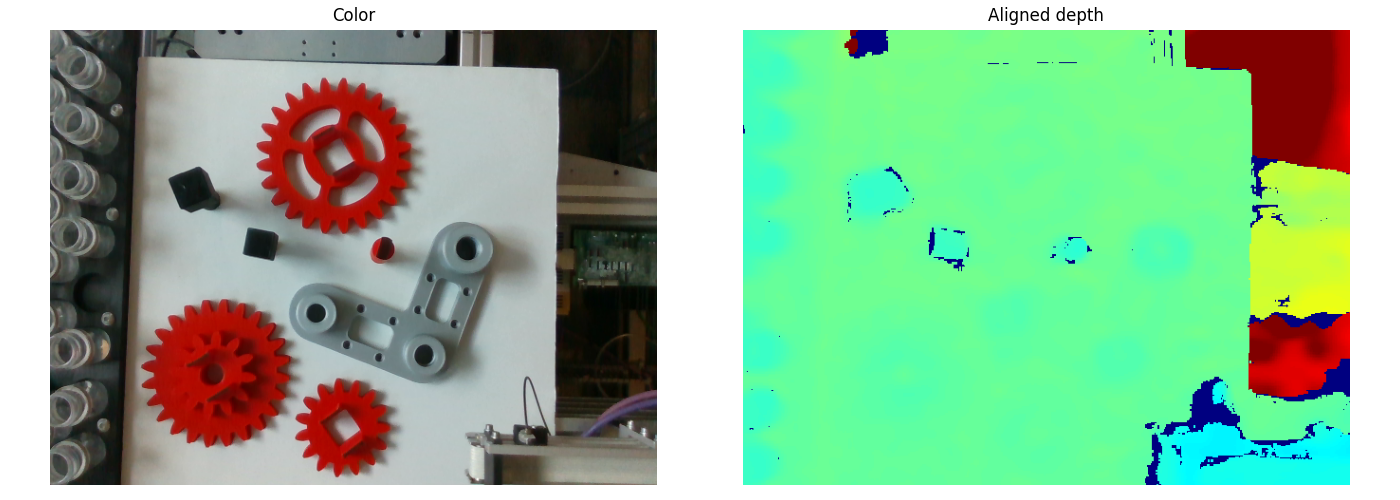

In [14]:
frames = align.process(pipeline.wait_for_frames())
color_frame = frames.get_color_frame()
depth_frame = frames.get_depth_frame()
if not color_frame or not depth_frame:
    raise RuntimeError("未获得有效的 aligned RGB-D 帧。")

preview_color = np.asanyarray(color_frame.get_data())
preview_depth_raw = np.asanyarray(depth_frame.get_data())
preview_depth_m = preview_depth_raw.astype(np.float32) * depth_scale
valid_preview_depth = preview_depth_m[preview_depth_m > 0]
preview_max_m = float(np.percentile(valid_preview_depth, 95)) if valid_preview_depth.size else 1.0
depth_vis = cv2.applyColorMap(
    cv2.convertScaleAbs(preview_depth_m, alpha=255 / max(preview_max_m, 1e-6)),
    cv2.COLORMAP_JET,
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(cv2.cvtColor(preview_color, cv2.COLOR_BGR2RGB)); axes[0].set_title("Color")
axes[1].imshow(cv2.cvtColor(depth_vis, cv2.COLOR_BGR2RGB)); axes[1].set_title("Aligned depth")
for ax in axes: ax.axis("off")
fig.tight_layout()
fig.savefig(output_dir / "preview_rgb_depth.png", dpi=150)
plt.show()


## Block 4：选择测试点

设置 `selection_mode='manual'` 后填写坐标，或设为 `'click'` 并在 RGB 图中点击。输出会显示 patch 边界。


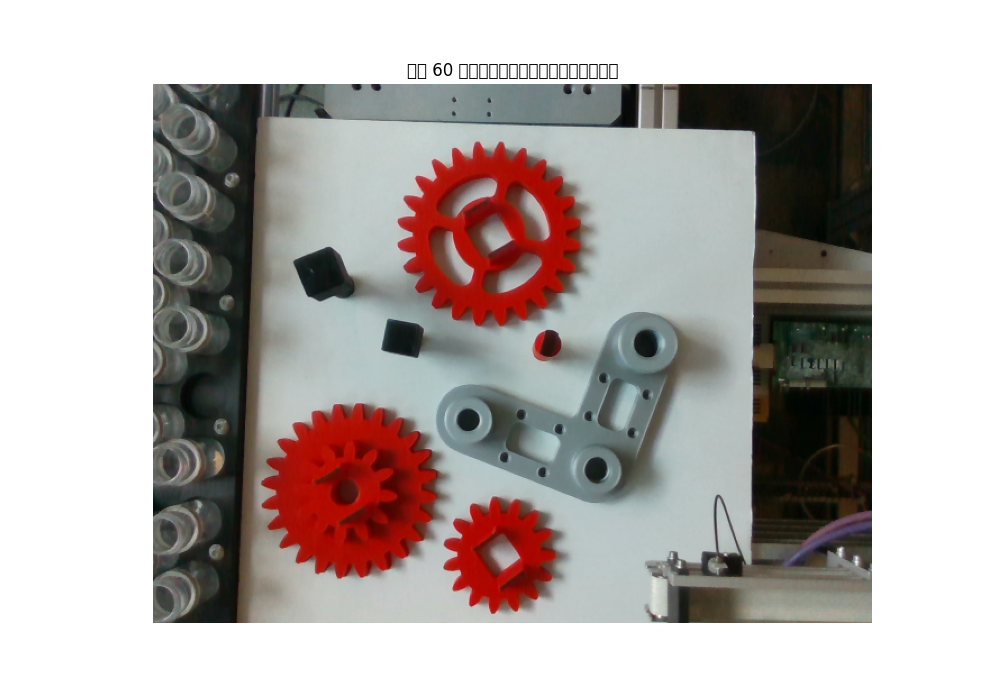

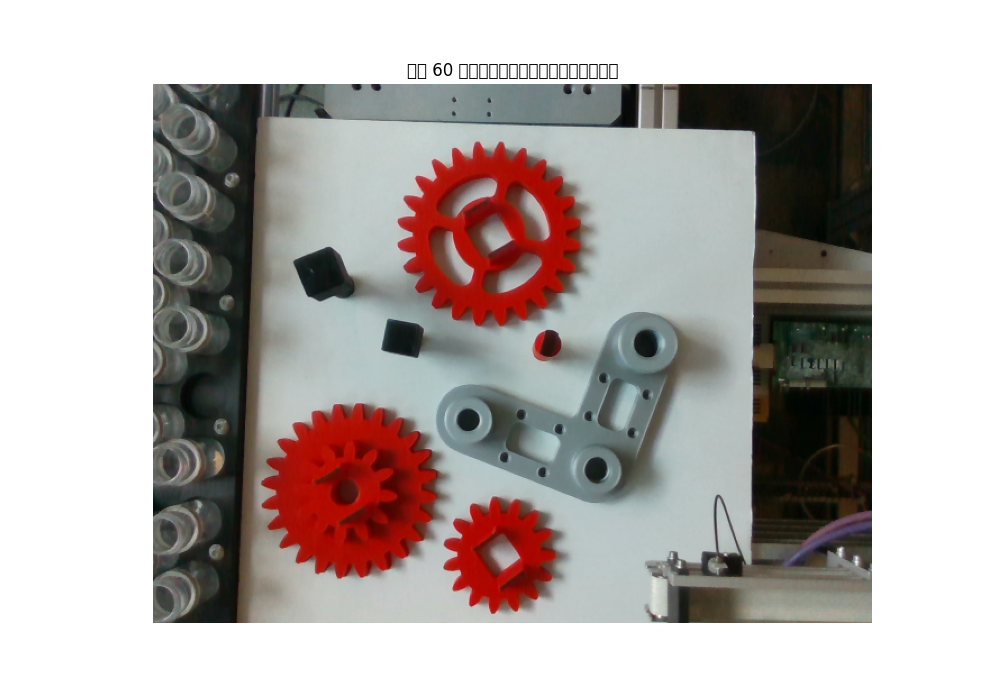

KeyboardInterrupt: 

In [16]:
selection_mode = "click"  # "manual" 或 "click"
manual_px, manual_py = width // 2, height // 2
click_timeout_s = 60

if selection_mode == "manual":
    px, py = int(manual_px), int(manual_py)
elif selection_mode == "click":
    backend = plt.get_backend().lower()
    interactive_backend = any(
        name in backend for name in ("ipympl", "widget", "nbagg")
    )
    if not interactive_backend:
        print(
            f"当前后端 {plt.get_backend()!r} 不支持点击，"
            f"自动使用手动坐标 ({manual_px}, {manual_py})。"
        )
        px, py = int(manual_px), int(manual_py)
    else:
        fig, ax = plt.subplots(figsize=(10, 7))
        ax.imshow(cv2.cvtColor(preview_color, cv2.COLOR_BGR2RGB))
        ax.set_title(
            f"请在 {click_timeout_s} 秒内点击一个平坦、无边缘的测试点"
        )
        ax.axis("off")
        fig.canvas.draw_idle()
        plt.show(block=False)

        clicked = plt.ginput(1, timeout=click_timeout_s, show_clicks=True)
        if not clicked:
            plt.close(fig)
            print(
                f"未收到点击，自动使用手动坐标 "
                f"({manual_px}, {manual_py})。"
            )
            px, py = int(manual_px), int(manual_py)
        else:
            px, py = map(lambda value: int(round(value)), clicked[0])
            plt.close(fig)
else:
    raise ValueError("selection_mode 只能是 'manual' 或 'click'。")

half = patch_size // 2
if not (half <= px < width - half and half <= py < height - half):
    raise ValueError("测试点太靠近图像边缘。")

selected_vis = preview_color.copy()
cv2.rectangle(
    selected_vis, (px-half, py-half), (px+half, py+half), (0, 255, 0), 2
)
cv2.drawMarker(
    selected_vis, (px, py), (0, 0, 255), cv2.MARKER_CROSS, 16, 2
)
plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(selected_vis, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title(f"Selected ({px}, {py}), patch={patch_size}x{patch_size}")
plt.show()
cv2.imwrite(str(output_dir / "selected_patch.png"), selected_vis)
print(f"已选择像素 ({px}, {py})。")

## Block 5：连续采集 100 帧

每帧保存单像素、patch median、patch mean 和 patch 有效像素比例；所有 0 depth 均被过滤。


In [ ]:
single_pixel_depth_list = []
patch_median_depth_list = []
patch_mean_depth_list = []
valid_pixel_ratio_list = []
timestamps_s = []

for frame_idx in range(num_frames):
    frames = align.process(pipeline.wait_for_frames())
    depth_frame = frames.get_depth_frame()
    if not depth_frame:
        single_pixel_depth_list.append(np.nan)
        patch_median_depth_list.append(np.nan)
        patch_mean_depth_list.append(np.nan)
        valid_pixel_ratio_list.append(0.0)
        timestamps_s.append(time.time())
        continue

    depth_raw = np.asanyarray(depth_frame.get_data())
    patch_raw = depth_raw[py-half:py+half+1, px-half:px+half+1]
    patch_m = patch_raw.astype(np.float64) * depth_scale
    valid_patch = patch_m[patch_raw > 0]
    single_raw = depth_raw[py, px]

    single_pixel_depth_list.append(single_raw * depth_scale if single_raw > 0 else np.nan)
    patch_median_depth_list.append(float(np.median(valid_patch)) if valid_patch.size else np.nan)
    patch_mean_depth_list.append(float(np.mean(valid_patch)) if valid_patch.size else np.nan)
    valid_pixel_ratio_list.append(float(valid_patch.size / patch_raw.size))
    timestamps_s.append(time.time())

print(f"完成 {num_frames} 帧采集。patch 有效像素比例均值: {np.mean(valid_pixel_ratio_list):.1%}")


## Block 6：统计和可视化

比较单像素与 patch median 的稳定性，绘制时序曲线和直方图。


In [ ]:
stats_single = depth_stats(single_pixel_depth_list)
stats_patch = depth_stats(patch_median_depth_list)
stats_df = pd.DataFrame([stats_single, stats_patch], index=["single_pixel", "patch_median"])
display_df = stats_df.copy()
for col in ["mean", "std", "min", "max", "peak_to_peak"]:
    display_df[col + "_mm"] = display_df[col] * 1000
display(display_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(np.asarray(single_pixel_depth_list) * 1000, ".-", label="single pixel", alpha=.75)
axes[0].plot(np.asarray(patch_median_depth_list) * 1000, ".-", label="patch median")
axes[0].set(xlabel="Frame", ylabel="Depth [mm]", title="Depth vs frame"); axes[0].legend(); axes[0].grid()
axes[1].hist(valid_values(single_pixel_depth_list) * 1000, bins=20, alpha=.6, label="single pixel")
axes[1].hist(valid_values(patch_median_depth_list) * 1000, bins=20, alpha=.6, label="patch median")
axes[1].set(xlabel="Depth [mm]", ylabel="Count", title="Depth histogram"); axes[1].legend(); axes[1].grid()
fig.tight_layout(); fig.savefig(output_dir / "noise_statistics.png", dpi=150); plt.show()


## Block 7：保存结果

保存逐帧 CSV、完整 NPZ、内参 JSON 和统计表，供后续 notebook 复用。


In [ ]:
import json

frame_df = pd.DataFrame({
    "frame": np.arange(num_frames), "timestamp_s": timestamps_s,
    "single_pixel_depth_m": single_pixel_depth_list,
    "patch_median_depth_m": patch_median_depth_list,
    "patch_mean_depth_m": patch_mean_depth_list,
    "valid_pixel_ratio": valid_pixel_ratio_list,
})
frame_df.to_csv(output_dir / "depth_noise_frames.csv", index=False)
stats_df.to_csv(output_dir / "depth_noise_statistics.csv")
np.savez_compressed(
    output_dir / "depth_noise_data.npz", **{c: frame_df[c].to_numpy() for c in frame_df.columns},
    px=px, py=py, patch_size=patch_size, depth_scale=depth_scale,
    intrinsics_json=json.dumps(intrinsics),
)
with open(output_dir / "camera_intrinsics.json", "w", encoding="utf-8") as f:
    json.dump(intrinsics, f, indent=2, ensure_ascii=False)
with open(SHARED_DIR / "camera_intrinsics.json", "w", encoding="utf-8") as f:
    json.dump(intrinsics, f, indent=2, ensure_ascii=False)
print("结果已保存到", output_dir.resolve())
print("共享内参已保存到", (SHARED_DIR / "camera_intrinsics.json").resolve())


## Block 8：结论提示与资源清理

依据 patch median 的标准差和峰峰值做初步诊断，并停止相机。


In [ ]:
std_mm = stats_patch["std"] * 1000
ptp_mm = stats_patch["peak_to_peak"] * 1000
if not np.isfinite(std_mm):
    print("结论：有效 depth 不足，先检查目标距离、反射材质、曝光和遮挡。")
elif std_mm < 2.0 and ptp_mm < 10.0:
    print(f"结论：patch median std={std_mm:.2f} mm，静态随机噪声较小。")
else:
    print(f"结论：std={std_mm:.2f} mm, peak-to-peak={ptp_mm:.2f} mm。")
    print("当前误差主要像随机/局部深度噪声；线性 scale/bias 校准前应先优化材质、距离、光照或滤波。")

pipeline.stop()
print("RealSense pipeline 已停止。")
